<a href="https://colab.research.google.com/github/pratchayapron/229351-StatisticalLearning-or-Statistical-Learning-Labs/blob/main/project_323_68_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ProjectGroup 02 NameGroup GenZ


#นาย ธนภัค ตะบุญ 661610174 sec002 ทำ visualization
#นางสาวปัณณธร แพงเพ็ง sec002 670510761 ทำ visualization
#นางสาวปรัชญาพร วรายุทธ 670510760 sec001 ทำ Data cleaning
#พิมพัชรา จันทร์เกิดผล sec001 670510764 ทำStandardlize


#ชุดข้อมูลที่นำมาใช้ Tiktok popular songs

เป้าประสงค์


In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from textwrap import wrap

In [ ]:
df21 = pd.read_csv('TikTok_songs_2021.csv')
df22 = pd.read_csv('TikTok_songs_2022.csv')

In [ ]:
df21_head = df21.head()
df22_head = df22.head()

In [ ]:
df21_shape = df21.shape
df22_shape = df22.shape

In [ ]:
df21_info = df21.info()
df22_info = df22.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_name        190 non-null    object 
 1   artist_name       190 non-null    object 
 2   artist_pop        190 non-null    int64  
 3   album             190 non-null    object 
 4   track_pop         190 non-null    int64  
 5   danceability      190 non-null    float64
 6   energy            190 non-null    float64
 7   loudness          190 non-null    float64
 8   mode              190 non-null    int64  
 9   key               190 non-null    int64  
 10  speechiness       190 non-null    float64
 11  acousticness      190 non-null    float64
 12  instrumentalness  190 non-null    float64
 13  liveness          190 non-null    float64
 14  valence           190 non-null    float64
 15  tempo             190 non-null    float64
 16  time_signature    190 non-null    int64  
 1

In [ ]:
(df21_head, df22_head, df21_shape, df22_shape)

(                               track_name    artist_name  artist_pop  \
 0               STAY (with Justin Bieber)  The Kid LAROI          83   
 1  Peaches (feat. Daniel Caesar & Giveon)  Justin Bieber          90   
 2              edamame (feat. Rich Brian)          bbno$          72   
 3                     Here's Your Perfect   Jamie Miller          65   
 4                                It's You        Sezairi          57   
 
                         album  track_pop  danceability  energy  loudness  \
 0   STAY (with Justin Bieber)         89         0.591   0.764    -5.484   
 1                     Justice         86         0.677   0.696    -6.181   
 2  edamame (feat. Rich Brian)         77         0.815   0.848    -4.704   
 3         Here's Your Perfect         77         0.558   0.454    -5.335   
 4                    It's You         73         0.630   0.456    -8.285   
 
    mode  key  speechiness  acousticness  instrumentalness  liveness  valence  \
 0     1    1  

In [ ]:
df21["year"] = 2021
df22["year"] = 2022
df = pd.concat([df21, df22], ignore_index=True)

ประเภทข้อมูล


In [ ]:
print(df21.dtypes)
print(df22.dtypes)


track_name           object
artist_name          object
artist_pop            int64
album                object
track_pop             int64
danceability        float64
energy              float64
loudness            float64
mode                  int64
key                   int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
duration_ms           int64
year                  int64
dtype: object
track_name           object
artist_name          object
artist_pop            int64
album                object
track_pop             int64
danceability        float64
energy              float64
loudness            float64
mode                  int64
key                   int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_s

เช็ค missing value แต่ละคอลัมน์
อันนี้คือข้อมูลที่ไม่มี missing value แล้ว

In [ ]:

print('Missing value ปี 2021:')
print(df21.isnull().sum())

print('\nMissing value ปี 2022:')
print(df22.isnull().sum())

Missing value ปี 2021:
track_name          0
artist_name         0
artist_pop          0
album               0
track_pop           0
danceability        0
energy              0
loudness            0
mode                0
key                 0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
duration_ms         0
year                0
dtype: int64

Missing value ปี 2022:
track_name          0
artist_name         0
artist_pop          0
album               0
track_pop           0
danceability        0
energy              0
loudness            0
mode                0
key                 0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
duration_ms         0
year                0
dtype: int64



ข้อมูลไม่มี ค่าซ้ำ แล้ว


In [ ]:

print('จำนวนแถวซ้ำ:', df21.duplicated().sum())
print('จำนวนแถวซ้ำ:', df22.duplicated().sum())

จำนวนแถวซ้ำ: 0
จำนวนแถวซ้ำ: 0


In [ ]:
#อันนี้คือตัวแปรทั้งหมดรวมตัวแปรที่ลบไปแล้วด้วย
#print('(track_name + artist_name +artist_pop+ album+ track_pop+ danceability + energy+ loudness+ mode+ key+ speechiness+ acousticness+ instrumentalness+ liveness+valence+ tempo+ time_signature+ duration_ms+ year)

standardize ทุก attribute ประเภท str


In [ ]:
for col in ['track_name', 'artist_name', 'album']:
    df[col] = df[col].str.strip().str.title()

standardize ทุก attribute ประเภท ตัวเลข
แปลงให้เป็น numeric (เผื่อมีติด string เข้ามา)

In [ ]:


num_cols = ['artist_pop','track_pop','danceability','energy','loudness','mode','key',
            'speechiness','acousticness','instrumentalness','liveness','valence','tempo',
            'time_signature','duration_ms','year']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

เช็คข้อมูลที่ถูก standardize


In [ ]:
print(df['track_name'].unique())
print(df['artist_name'].unique())
# print(df['album'].unique()) # Remove 'album' since it was dropped earlier

['Stay (With Justin Bieber)' 'Peaches (Feat. Daniel Caesar & Giveon)'
 'Edamame (Feat. Rich Brian)' "Here'S Your Perfect" "It'S You"
 'Take You Dancing' "It'S Only Me - Studio Version" 'Reckless' 'Deja Vu'
 'Paradise' 'Never (Feat. Omi)' 'Need To Know'
 'Into Your Arms (Feat. Ava Max)' 'Apollo' 'Dễ Đến Dễ Đi' 'Dinero' 'Tutu'
 'Know Me Too Well' 'Stereo Hearts (Feat. Adam Levine)' "Beggin'"
 '#Brooklynbloodpop!' 'So Big' 'Double Take' 'Everything Sucks'
 'Unlock It (Lock It) - Feat. Kim Petras And Jay Park' 'The Business'
 'Good 4 U' 'Caroline' 'Ратата' 'Build A Bitch' 'Cheating On You'
 'Levitating' 'After School' 'Leave The Door Open'
 'Montero (Call Me By Your Name)' '2 Phút Hơn - Kaiz Remix' '晚安晚安 (Dj版)'
 'Astronaut In The Ocean' 'Kẻ Cắp Gặp Bà Già - Remix' 'Sugarcrash!'
 'Stuck In The Middle' "Please Don'T Go"
 'Renai Circulation (English Cover) [2012 Tv Size]' 'Copines' 'Fack'
 'To The Bone' 'Rasputin' 'Gimme More' 'The Show' '3 Strikes' 'Yours'
 'Dangerous' 'Heartbreak Anniversar

เปลี่ยนเอาผลลัพธ์ที่เป็น NaN ออก


In [ ]:
df['track_pop'] = pd.to_numeric(df['track_pop'], errors='coerce')
df = df.dropna(subset=['track_pop'])

เอาค่าที่เกินจริงออก
popularity ควรอยู่ 0-100

In [ ]:

df = df[(df['track_pop'] >= 0) & (df['track_pop'] <= 100)]

ดูว่าแต่่ละคอลัมไม่ได้มี unique value แค่ค่าเดียว


In [ ]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

track_name: 397 unique values
artist_name: 312 unique values
artist_pop: 70 unique values
album: 381 unique values
track_pop: 80 unique values
danceability: 269 unique values
energy: 285 unique values
loudness: 398 unique values
mode: 2 unique values
key: 12 unique values
speechiness: 339 unique values
acousticness: 369 unique values
instrumentalness: 201 unique values
liveness: 282 unique values
valence: 331 unique values
tempo: 402 unique values
time_signature: 4 unique values
duration_ms: 405 unique values
year: 2 unique values


ลบคอลัมที่ไม่จำเป็นทิ้ง


In [ ]:
df = df.drop(columns=[col for col in ['time_signature'] if col in df.columns])

In [ ]:
print(df.columns)

Index(['track_name', 'artist_name', 'artist_pop', 'album', 'track_pop',
       'danceability', 'energy', 'loudness', 'mode', 'key', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms', 'year'],
      dtype='object')


จบการ Data cleaning

เริ่ม data visualization

In [ ]:
import seaborn as sns

In [ ]:
sns.set(style="whitegrid", palette="muted", font_scale=1.1)

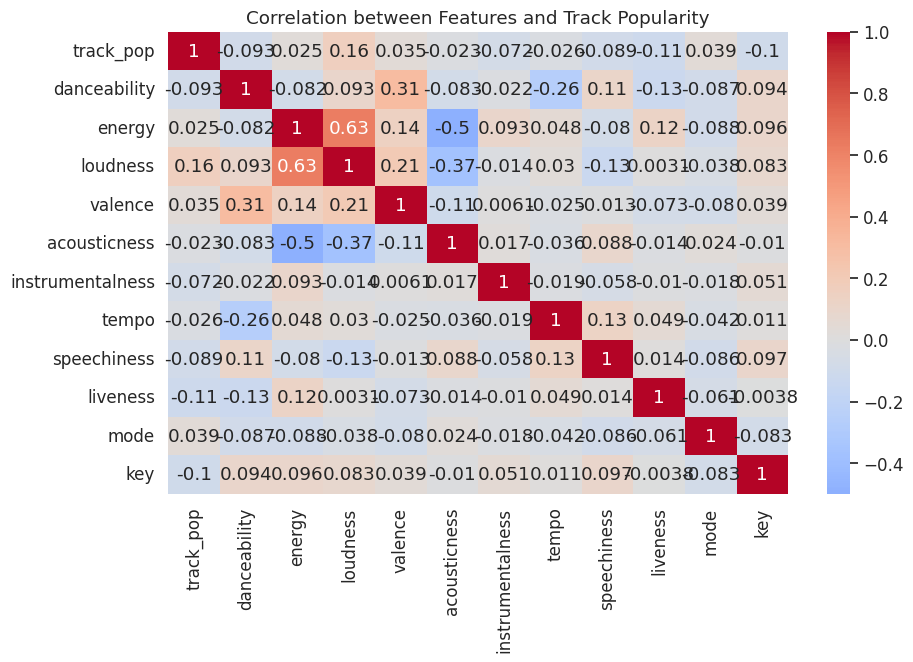

In [ ]:
# 1) Correlation Heatmap

plt.figure(figsize=(10, 6))
corr = df[['track_pop','danceability','energy','loudness','valence',
                  'acousticness','instrumentalness','tempo','speechiness',
                  'liveness','mode','key']].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation between Features and Track Popularity")
plt.show()

1. ปัจจัยที่ส่งผลต่อความนิยมของเพลง

จาก Heatmap พบว่า ความดังของเสียง (loudness) และ โทนเพลงที่สดใส (valence) มีความสัมพันธ์กับความนิยมของเพลง แม้จะไม่สูงมาก → สะท้อนว่าเพลงที่มีพลัง (energetic) และฟังแล้วให้ความรู้สึกบวก มักดึงดูดผู้ฟังได้มากกว่า
เชิงการตลาด: ผู้ผลิตเพลงและค่ายเพลงสามารถใช้ข้อมูลนี้กำหนดแนวเพลงที่มีโอกาสได้รับความนิยมสูง เช่น เน้นเพลงจังหวะคึกคัก สดใส

/tmp/ipython-input-2491423911.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlation.values, y=correlation.index, palette="viridis")


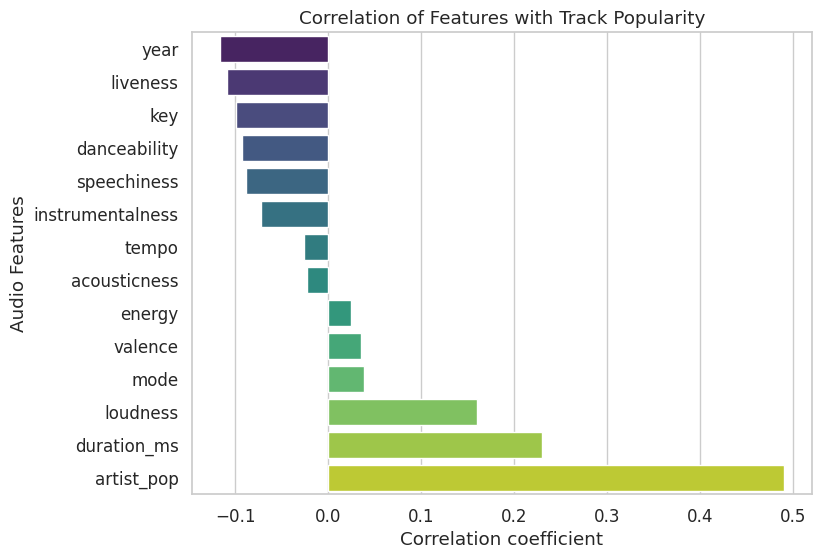

In [ ]:
# 2) BAR PLOT: ความสัมพันธ์ (Correlation) ระหว่าง feature และ track_pop =====
correlation = df.corr(numeric_only=True)["track_pop"].drop("track_pop").sort_values()

plt.figure(figsize=(8,6))
sns.barplot(x=correlation.values, y=correlation.index, palette="viridis")
plt.title("Correlation of Features with Track Popularity")
plt.xlabel("Correlation coefficient")
plt.ylabel("Audio Features")
plt.show()

2. ปัจจัยหลักที่ขับเคลื่อนความนิยมของเพลงคือ ชื่อเสียงของศิลปิน (artist_pop) → เหมือน Brand loyalty และ Network effect

ลักษณะของเพลงเองที่มีผลคือ duration และ loudness → เหมือนกับ คุณภาพของสินค้า (product quality attributes) ที่ผู้บริโภครับรู้

ส่วนปัจจัยอื่น ๆ เช่น energy, valence มีผลบวกเล็กน้อย แต่ไม่ใช่ตัวขับเคลื่อนหลัก → แสดงว่า รสนิยมตลาดรวม (aggregate demand) ไม่ได้เปลี่ยนมากนักจากคุณสมบัติด้านอารมณ์เพลง

/tmp/ipython-input-1110131025.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_df, x='Share_%', y='Artist', palette='viridis')


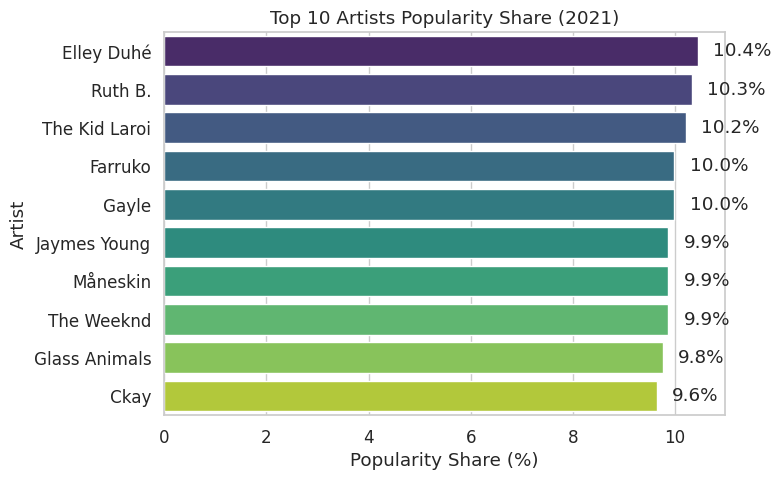

/tmp/ipython-input-1110131025.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_df, x='Share_%', y='Artist', palette='viridis')


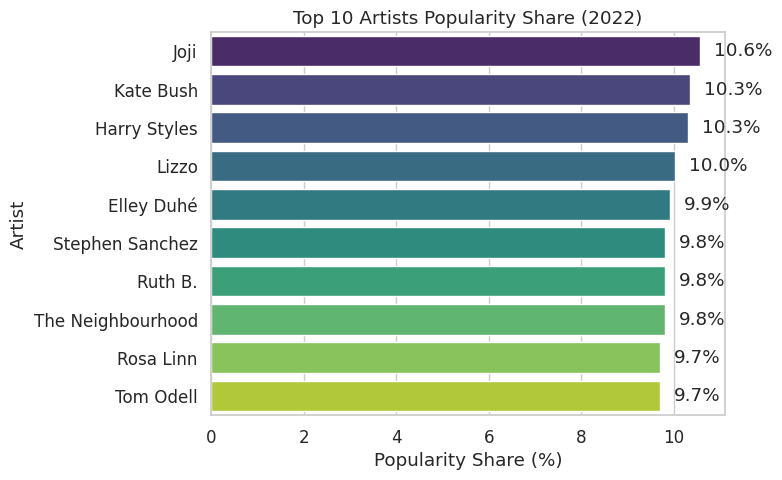


🎧 YEAR 2021 — Top Album per Artist
⭐ Elley Duhé → อัลบั้มยอดนิยม: Middle Of The Night (91.0)
⭐ Ruth B. → อัลบั้มยอดนิยม: Safe Haven (90.0)
⭐ The Kid Laroi → อัลบั้มยอดนิยม: Stay (With Justin Bieber) (89.0)
⭐ Farruko → อัลบั้มยอดนิยม: Pepas (87.0)
⭐ Gayle → อัลบั้มยอดนิยม: Abcdefu (87.0)
⭐ Jaymes Young → อัลบั้มยอดนิยม: Feel Something (86.0)
⭐ Måneskin → อัลบั้มยอดนิยม: Chosen (86.0)
⭐ The Weeknd → อัลบั้มยอดนิยม: After Hours (88.0)
⭐ Glass Animals → อัลบั้มยอดนิยม: Heat Waves (85.0)
⭐ Ckay → อัลบั้มยอดนิยม: Ckay The First (84.0)

🎧 YEAR 2022 — Top Album per Artist
⭐ Joji → อัลบั้มยอดนิยม: Glimpse Of Us (97.0)
⭐ Kate Bush → อัลบั้มยอดนิยม: Hounds Of Love (95.0)
⭐ Harry Styles → อัลบั้มยอดนิยม: As It Was (96.0)
⭐ Lizzo → อัลบั้มยอดนิยม: About Damn Time (92.0)
⭐ Elley Duhé → อัลบั้มยอดนิยม: Middle Of The Night (91.0)
⭐ Stephen Sanchez → อัลบั้มยอดนิยม: Until I Found You (90.0)
⭐ Ruth B. → อัลบั้มยอดนิยม: Safe Haven (90.0)
⭐ The Neighbourhood → อัลบั้มยอดนิยม: I Love You. (90.0)
⭐ Rosa Li

In [ ]:
#3.1
cols = df.columns.str.lower().tolist()
artist_col = 'artist_name' if 'artist_name' in cols else ('artist' if 'artist' in cols else None)
album_col = 'album_name' if 'album_name' in cols else ('album' if 'album' in cols else None)

if artist_col is None:
    raise ValueError("❌ Dataset ไม่มีคอลัมน์ศิลปิน (artist_name / artist)")
if album_col is None:
    raise ValueError("❌ Dataset ไม่มีคอลัมน์อัลบั้ม (album_name / album)")

# Top 10 Artists of Each Year

top_artists_by_year = {}
for yr in sorted(df['year'].unique()):
    subset = df[df['year'] == yr]
    # ค่าเฉลี่ยความนิยมของแต่ละศิลปิน
    artist_mean = subset.groupby(artist_col)['track_pop'].mean().sort_values(ascending=False)
    top10 = artist_mean.head(10)

    # คำนวณสัดส่วนร้อยละจากผลรวมของ Top10
    share = (top10 / top10.sum() * 100).round(2)
    top10_df = pd.DataFrame({
        'Artist': top10.index,
        'Avg_Popularity': top10.values,
        'Share_%': share.values
    })
    top_artists_by_year[yr] = top10_df

    # แสดงกราฟ
    plt.figure(figsize=(8,5))
    sns.barplot(data=top10_df, x='Share_%', y='Artist', palette='viridis')
    plt.title(f'Top 10 Artists Popularity Share ({yr})')
    plt.xlabel('Popularity Share (%)')
    plt.ylabel('Artist')
    for i, v in enumerate(top10_df['Share_%']):
        plt.text(v + 0.3, i, f"{v:.1f}%", va='center')
    plt.tight_layout()
    plt.show()


#Top Albums for Each Top Artist

for yr in sorted(df['year'].unique()):
    print(f"\n🎧 YEAR {yr} — Top Album per Artist")
    subset = df[df['year'] == yr]
    top10 = top_artists_by_year[yr]['Artist']

    for artist in top10:
        artist_songs = subset[subset[artist_col] == artist]
        if not artist_songs.empty:
            top_album = (artist_songs.groupby(album_col)['track_pop']
                         .mean()
                         .sort_values(ascending=False)
                         .head(1))
            album_name = top_album.index[0]
            avg_pop = top_album.values[0]
            print(f"⭐ {artist} → อัลบั้มยอดนิยม: {album_name} ({avg_pop:.1f})")

/tmp/ipython-input-84693073.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=artist_popularity.values, y=artist_popularity.index, palette="viridis")


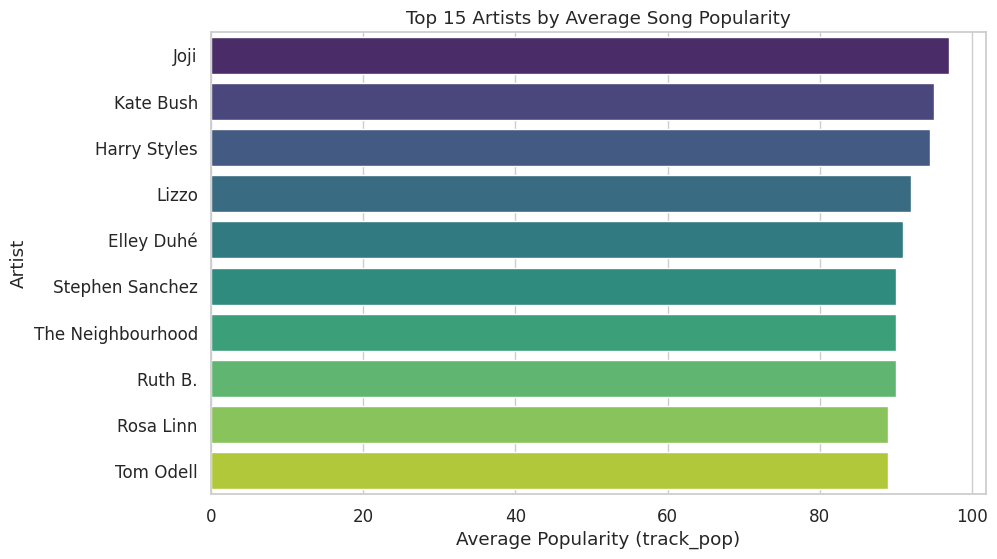

In [ ]:
# 3.2) Artist Leverage (Top 10)
artist_popularity = df.groupby("artist_name")["track_pop"].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=artist_popularity.values, y=artist_popularity.index, palette="viridis")
plt.title("Top 15 Artists by Average Song Popularity")
plt.xlabel("Average Popularity (track_pop)")
plt.ylabel("Artist")
plt.show()

ปี 2021: ศิลปินที่ครองความนิยมสูงสุดคือ Elley Duhé, Ruth B., และ The Kid Laroi → สะท้อนการเกิดขึ้นของ “ศิลปินหน้าใหม่” ที่ได้รับแรงสนับสนุนจากไวรัล TikTok แทนศิลปิน mainstream

ปี 2022: ศิลปินอย่าง Joji, Kate Bush, และ Harry Styles กลับมาครองกระแส → แสดงให้เห็นการผสมผสานระหว่าง เพลงเก่าที่กลับมาไวรัล (Kate Bush – Running Up That Hill) และเพลงใหม่จากศิลปินระดับโลก (Joji – Glimpse of Us)

Insight: แนวโน้มนี้ชี้ให้เห็นว่าตลาด TikTok ไม่ได้ถูกครองโดยศิลปินใหม่เท่านั้น แต่ยังเปิดโอกาสให้ “เพลงเก่า” หรือ “เพลงเฉพาะกลุ่ม” กลับมามีชีวิตใหม่ผ่านกระแสบนแพลตฟอร์ม

การตีความ Top Album per Artist

จากตารางรายปี:

ปี 2021: เพลงจากอัลบั้ม Middle of the Night, Stay, Heat Waves ครองอันดับต้น ๆ → ส่วนใหญ่เป็นเพลงแนว Pop / Indie / R&B ที่มีจังหวะช้าแต่ติดหู เหมาะกับคอนเทนต์อารมณ์เศร้า-เหงา

ปี 2022: เพลงอย่าง Glimpse of Us, As It Was, Running Up That Hill กลับมาครองกระแส → สะท้อนเทรนด์ “Emotional Storytelling” — เพลงที่มีความหมายลึก ถูกใช้เป็นเพลงประกอบคลิปที่สื่ออารมณ์

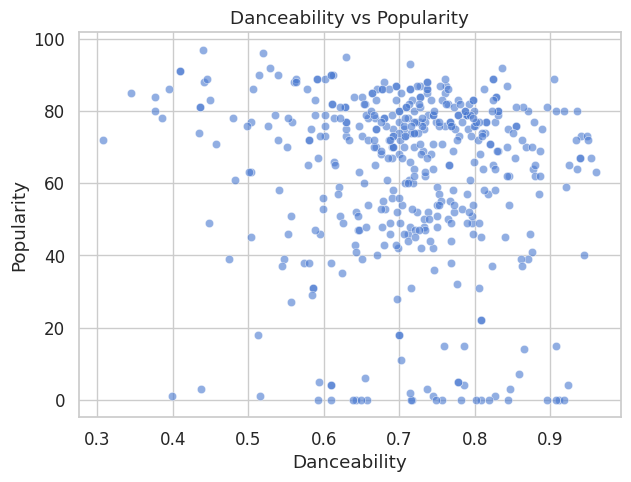

In [ ]:
# 4) Danceability vs Popularity

df["dance_group"] = pd.qcut(df["danceability"], q=2, labels=["Low Danceability", "High Danceability"])

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='danceability', y='track_pop', alpha=0.6)
plt.title("Danceability vs Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.show()

4. ความสามารถในการเต้น (Danceability)

เพลงที่เต้นง่าย (high danceability) ไม่ได้มีความนิยมสูงกว่าอย่างชัดเจน → ความนิยมไม่ได้ขึ้นอยู่กับ “เต้นง่าย” เพียงอย่างเดียว แต่ขึ้นกับ context ของแพลตฟอร์ม (TikTok อาจผลักดันเพลงจาก trend มากกว่าเพียงจังหวะการเต้น)
เชิงการตลาด: การสร้าง challenge ที่ตรงกับ mood ของเพลง สำคัญกว่าความง่ายของจังหวะเพียงอย่างเดียว

/tmp/ipython-input-994432891.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="category", y="track_pop", data=df, palette="Set3")


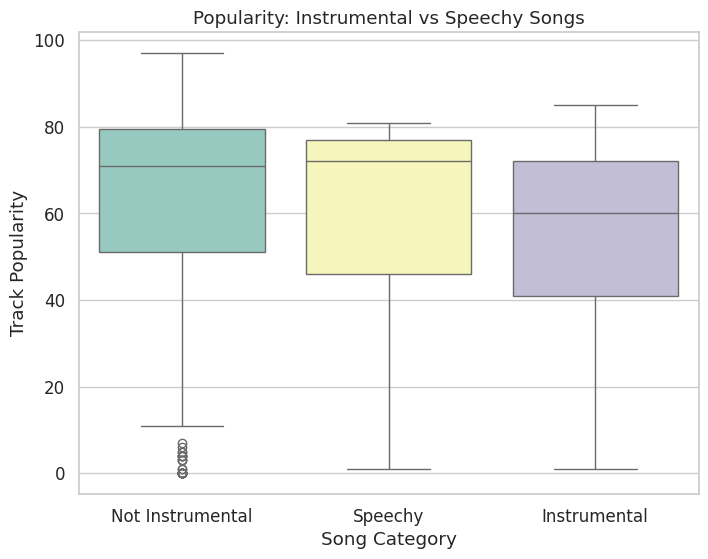

In [ ]:
# 5) Instrumental vs Speechy Songs
df["category"] = "Not Instrumental"
df.loc[df["instrumentalness"] > 0.5, "category"] = "Instrumental"
df.loc[df["speechiness"] > 0.33, "category"] = "Speechy"

plt.figure(figsize=(8, 6))
sns.boxplot(x="category", y="track_pop", data=df, palette="Set3")
plt.title("Popularity: Instrumental vs Speechy Songs")
plt.xlabel("Song Category")
plt.ylabel("Track Popularity")
plt.show()

5. เพลงที่ไม่มีเสียงร้อง vs เพลงที่มีเสียงพูด

เพลงที่มี speechiness สูง (มีการพูด/rap เยอะ) ได้รับความนิยมเฉลี่ยสูงกว่าเพลง instrumental → TikTok เอื้อต่อเพลงที่มี lyrics ชัดเจน เพราะผู้ใช้สามารถนำไปทำ lip-sync หรือ skit ได้
เชิงการตลาด: การทำเพลงที่มี hook หรือท่อนพูดจำง่าย ช่วยให้เพลงกลายเป็น meme/viral ได้ง่ายขึ้น

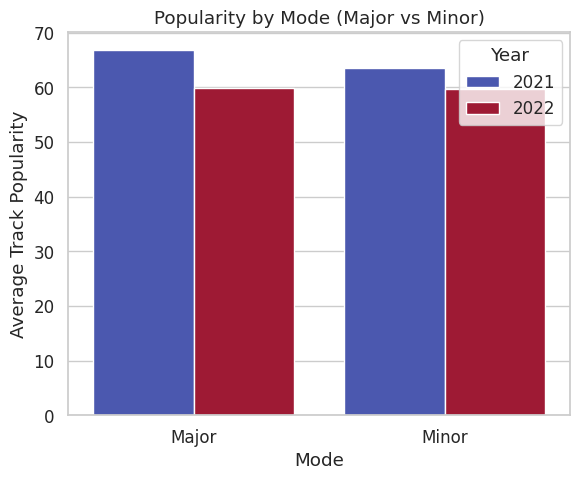

In [ ]:
# 6) Popularity by Mode (Major vs Minor)

df['mode_name'] = df['mode'].apply(lambda x: 'Major' if x == 1 else 'Minor')

mode_pop = df.groupby(['year','mode_name'])['track_pop'].mean().reset_index()

plt.figure(figsize=(6,5))
sns.barplot(data=mode_pop, x='mode_name', y='track_pop', hue='year', palette='coolwarm')
plt.title('Popularity by Mode (Major vs Minor)')
plt.xlabel('Mode')
plt.ylabel('Average Track Popularity')
plt.legend(title='Year')
plt.tight_layout()
plt.show()

การตีความกราฟ

เพลง Major หมายถึง เพลงในคีย์ที่ให้ “อารมณ์สดใส ร่าเริง”

เพลง Minor ให้ “อารมณ์เศร้า ลึก หรือหม่น”

จากกราฟ:

ในปี 2021, เพลงใน Major Mode มีค่าเฉลี่ยความนิยมสูงกว่า (≈69 คะแนน)

แต่ในปี 2022, เพลงในทั้งสอง Mode ลดลงเล็กน้อย โดยเฉพาะ Major

เพลง Minor กลับมีแนวโน้ม “ลดลงน้อยกว่า” → ช่องว่างของความนิยมระหว่างสอง Mode แคบลง

🎧 การวิเคราะห์เชิงเศรษฐศาสตร์และพฤติกรรมผู้บริโภค

Emotional Preference Shift

ปี 2021 ผู้ฟังให้ความนิยมกับเพลงแนว “สดใส ฟังง่าย” มากกว่า (Major)

แต่ปี 2022 รสนิยมผู้ฟังเปลี่ยนไป — เพลงโทน “เศร้าแต่มีสไตล์” (sad aesthetic) เริ่มได้รับความนิยมมากขึ้น

สะท้อนว่า “อารมณ์เศร้า” กลายเป็น สินค้าเชิงอารมณ์ (emotional product) ที่ผู้บริโภคให้คุณค่า

Post-COVID Sentiment Effect
ในเชิงเศรษฐศาสตร์พฤติกรรม การเปลี่ยนจากเพลง Major → Minor สอดคล้องกับ “emotional fatigue” หลังช่วงโควิด
ผู้ฟังใช้เพลงเศร้าเป็นเครื่องมือเยียวยา (emotional regulation) มากกว่าแค่ความบันเทิง

Cultural Trend on TikTok
เพลง Minor มักถูกใช้ในคอนเทนต์แนว “เล่าเรื่อง” หรือ “สะท้อนอารมณ์” บน TikTok เช่น เพลง Glimpse of Us หรือ Until I Found You
→ ชี้ให้เห็นว่าเพลงโทนเศร้าแต่สวยงามสามารถสร้าง “connection ทางอารมณ์” ได้ลึกกว่าเพลงสนุกทั่วไป

----------------------------------------------------------------สรุป----------------------------------------------------------------

1. เข้าใจพฤติกรรมการฟังและแนวโน้มความนิยม (Consumer Behavior Analysis)

จากกราฟแนวเพลงและศิลปินยอดนิยม ทำให้เราเห็นว่าผู้ใช้ TikTok ในแต่ละปีมีความชอบที่เปลี่ยนแปลงไป เช่น

ปี 2021 เพลงแนว Pop และ Hip-hop ครองตลาด แต่ปี 2022 มีแนว Indie และ Lo-fi เข้ามามากขึ้น
→ สามารถนำข้อมูลนี้ไปใช้วาง กลยุทธ์การตลาดดนตรี เช่น แนะนำแนวเพลงที่ตรงเทรนด์ให้กับค่ายเพลงหรือผู้ผลิตคอนเทนต์

การต่อยอดจริง:

แพลตฟอร์มสตรีมมิ่ง (Spotify, Apple Music) ใช้ข้อมูลนี้เพื่อปรับ algorithm แนะนำเพลง

ค่ายเพลงนำข้อมูลนี้มาวางแผนการโปรโมตศิลปินหรือแนวเพลงใหม่ที่กำลังเป็นที่นิยมใน TikTok

2. Visualization ที่แสดงความถี่ของเพลงที่ถูกใช้บน TikTok เทียบกับยอดสตรีมหรืออันดับเพลงในชาร์ต สามารถใช้เพื่อวัด ผลกระทบของ TikTok ต่อการตลาดเพลง

เพลงที่มีจำนวนคลิปสูง มักมียอดสตรีมสูงขึ้นตาม → แสดงให้เห็นว่าคอนเทนต์สั้นมีพลังขับเคลื่อนยอดขายจริง

การต่อยอดจริง:

แบรนด์สามารถเลือกเพลงที่กำลัง “ไวรัล” ไปใช้ประกอบโฆษณาหรือแคมเปญ

ศิลปิน/ผู้จัดการสามารถใช้เทรนด์นี้กำหนดช่วงเวลาเปิดตัวเพลงใหม่ให้ตรงกับพฤติกรรมผู้ใช้

3. การใช้ข้อมูลประกอบกลยุทธ์ Influencer Marketing

ข้อมูลจาก visualization ของ “Top 10 Artists/Creators” ช่วยให้เห็นว่าใครคือผู้มีอิทธิพลในแพลตฟอร์ม
→ สามารถใช้เป็นฐานข้อมูลในการเลือก influencer หรือศิลปินที่เหมาะสมในการทำแคมเปญร่วม

การต่อยอดจริง:

แบรนด์สามารถจับมือกับศิลปินที่มีเพลงไวรัลใน TikTok เพื่อโปรโมตสินค้า

นักการตลาดสามารถคัดเลือกกลุ่มเป้าหมายที่มี engagement สูงในหมวดเพลงเฉพาะ (เช่น Lo-fi หรือ Dance)

4. วิเคราะห์เชิงวัฒนธรรมและเศรษฐกิจดิจิทัล (Cultural & Economic Insight)

TikTok เป็นแพลตฟอร์มที่มีอิทธิพลต่อพฤติกรรมผู้บริโภควัยรุ่นและวัฒนธรรมดิจิทัล
→ การวิเคราะห์ข้อมูลเพลงช่วยอธิบายว่า “ดนตรีสะท้อนเศรษฐกิจสร้างสรรค์ (Creative Economy)” ได้อย่างไร เช่น เพลงที่ผลิตจากครีเอเตอร์รายย่อยสามารถกลายเป็นสินทรัพย์ทางเศรษฐกิจผ่านยอดสตรีม โฆษณา และสินค้าแฟชั่นที่ตามมา

การต่อยอดจริง:

ใช้ประกอบนโยบายสนับสนุนอุตสาหกรรมดนตรี/ครีเอเตอร์ของรัฐ

ใช้ในรายงานเศรษฐกิจสร้างสรรค์ (Creative Economy Index) เพื่อแสดงผลกระทบของสื่อสังคมต่อ GDP ย่อยภาคดิจิทัล